## 1. Churn Prediction Project

We start a new project: predicting customer churn for a telecom company.  
In this first section we look at the problem statement, how churn prediction fits into machine learning as binary classification, and the dataset we will work with for the whole chapter.

### The problem of churn

Churn is when a customer stops using a service.  
A telecom company has many customers, and every month some of them decide to terminate their contracts and switch to another provider.  
Losing customers is expensive, so the company wants to identify the people who are likely to leave before they actually do.

The idea is simple: **for every customer, we compute a score between 0 and 1 (the probability that this customer is about to churn)**. Then the company can target the customers with high scores and try to retain them, for example by sending an email with discounts or special promotions.

### Classification

To predict this score we use machine learning.  
The task is binary classification: we look at one customer and predict one of two possible outcomes.  
For the i-th customer, we want our model $g$ to approximate the target $y$:

$$g(x_i) \approx y_i$$

Here $x$ is the feature vector (everything we know about the customer) and $y$ is the target variable. The **target is binary**, **so $y$ belongs to $\{0, 1\}$**:
- **1** is the positive class: **the customer churned**
- **0** is the negative class: **the customer stayed**

The **output of the model (the score) is the likelihood of churning**. In this project, 1 means the customer left the company and 0 means the customer stayed.

We learn $g$ from historical data.  
We take the customers of the previous month (we already know what happened to them).  
For each of them we know the demographics, what services they use, what kind of contract they have and how much they pay, and we know whether they stayed or left.  
The model finds the patterns in this data, and then we apply it to the current customers to score them.

### The dataset

For this project we use the [Telco Customer Churn dataset from Kaggle](https://www.kaggle.com/blastchar/telco-customer-churn). It contains information about customers of a telecom company and whether they churned.
Each row is one customer. The columns describe:
- Customer ID
- Demographics: gender, whether the customer is a senior citizen, whether they have a partner and dependents
- Services: phone service, multiple lines, internet service, online security, online backup, device protection, tech support, streaming TV and streaming movies
- Account information: contract type, paperless billing, payment method
- Charges: monthly and total charges
- Tenure: the number of months the customer has stayed with the company
- Churn: the target , i.e. whether the customer left

The whole chapter walks through this project step by step: we prepare the data, set up a validation framework, do EDA and feature importance analysis, then train a **logistic regression model** and use it to score customers.

### Logistic Regression?!

**Logistic regression is a specific algorithm used to solve classification problems**. While "classification" is an entire category of machine learning tasks dedicated to predicting discrete class labels (like Spam vs. Not Spam), Logistic Regression is one particular mathematical tool used to achieve that goal.

To understand how they relate, it helps to separate the overall objective from the specific technique:
- **Classification (The Task)**: A broad problem domain in supervised learning where the goal is to sort data points into distinct, predefined categories. Examples of classification algorithms include Decision Trees, Random Forests, Support Vector Machines (SVM), Naive Bayes, and Logistic Regression.
- **Logistic Regression (The Tool)**: A specific statistical model that maps a linear combination of input features to a value between 0 and 1 using the sigmoid function. Strictly speaking, it is a regression model because it outputs a continuous numerical value: the probability of an item belonging to a certain class.

## 2. Data Preparation

In this section we download the churn dataset, read it with pandas and prepare it for machine learning: make the column names and values uniform, fix the column that pandas reads incorrectly, and translate the target variable to numbers.

In [50]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

### Downloading and reading the data

In [4]:
data = 'https://raw.githubusercontent.com/k-candidate/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'
!wget -nc $data -O data-week-3.csv

--2026-10-16 10:24:01--  https://raw.githubusercontent.com/k-candidate/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.108.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 977501 (955K) [text/plain]
Saving to: ‘data-week-3.csv’

data-week-3.csv     100%[===================>] 954,59K  --.-KB/s    in 0,06s   

2026-10-16 10:24:02 (16,7 MB/s) - ‘data-week-3.csv’ saved [977501/977501]



In [5]:
df = pd.read_csv('data-week-3.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
# The dataframe has 21 columns. With this many columns, `df.head()` hides some of them behind `...` in the middle.
# To see all of them at once we can transpose the dataframe (flip rows and columns) with `df.head().T`.
df.head().T

,0,1,2,3,4
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,No,No,No
Dependents,No,No,No,No,No
tenure,1,34,2,45,2
PhoneService,No,Yes,Yes,No,Yes
MultipleLines,No phone service,No,No,No phone service,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic
OnlineSecurity,No,Yes,Yes,Yes,No


### Making everything uniform

The column names are inconsistent: some start with an uppercase letter (`CustomerID`, `Tenure`), some contain spaces (`Monthly Charges` is `MonthlyCharges` here, but the values inside columns do contain spaces). The values are also inconsistent: we see `No`, `Yes`, `No phone service` and so on.  
We lowercase everything and replace spaces with underscores:

In [8]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [9]:
# We lowercase everything and replace spaces with underscores
df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

In [11]:
df.head().T

,0,1,2,3,4
customerid,7590-vhveg,5575-gnvde,3668-qpybk,7795-cfocw,9237-hqitu
gender,female,male,male,male,female
seniorcitizen,0,0,0,0,0
partner,yes,no,no,no,no
dependents,no,no,no,no,no
tenure,1,34,2,45,2
phoneservice,no,yes,yes,no,yes
multiplelines,no_phone_service,no,no,no_phone_service,no
internetservice,dsl,dsl,dsl,dsl,fiber_optic
onlinesecurity,no,yes,yes,yes,no


### Fixing the totalcharges column

Two things stand out:
- `seniorcitizen` is `int64`: it is stored as 0/1 instead of yes/no. That's fine, we will treat it as a categorical variable later.
- `totalcharges` is `str` although it clearly contains numbers.

In [12]:
# Let's try to convert totalcharges to numeric
pd.to_numeric(df['totalcharges'])

ValueError: Unable to parse string "_" at position 488

In [13]:
# ValueError: Unable to parse string "_" at position 488
# The reason: in the original data, missing values in this column were encoded with a space. 
# Our normalization step replaced spaces with underscores, so the missing values became "_", and pandas cannot parse that as a number.
# We can force conversion with `errors='coerce`. Unparseable strings are then replaced with NaN
tc = pd.to_numeric(df.totalcharges, errors='coerce')

In [14]:
# Let's see how many missing values this creates:
tc.isnull().sum()

np.int64(11)

In [16]:
# Let's inspect these missing values
df[tc.isnull()][['customerid', 'totalcharges']]

,customerid,totalcharges
488,4472-lvygi,_
753,3115-czmzd,_
936,5709-lvoeq,_
1082,4367-nuyao,_
1340,1371-dwpaz,_
3331,7644-omvmy,_
3826,3213-vvolg,_
4380,2520-sgtta,_
5218,2923-arzlg,_
6670,4075-wkniu,_


In [17]:
# These are customers who just joined - their tenure is small and they haven't been billed yet, so their total charges are not available. 
# For them we simply fill the missing values with zero.
# Zero is not always the best replacement, but in this case it is acceptable: it matches the fact that these customers haven't paid anything yet.
df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

### Encoding the target variable

In [18]:
# The target `churn` still contains strings:
df.churn.head()

0     no
1     no
2    yes
3     no
4    yes
Name: churn, dtype: str

In [19]:
# For classification, we need numbers. We compare the column with `'yes'`.
# This produces a boolean series, and cast it to integers
df.churn = (df.churn == 'yes').astype(int)

In [20]:
# Now `churn` is `1` for customers who churned and `0` for those who stayed.
df.churn.head()

0    0
1    0
2    1
3    0
4    1
Name: churn, dtype: int64

## 3. Setting up the validation framework

**Before training anything, we split the data into train, validation and test sets using Scikit-Learn, and we put the target variable aside so it cannot leak into the features.**

### Splitting the data

We use `train_test_split` from `sklearn.model_selection`:

In [21]:
from sklearn.model_selection import train_test_split

We want the classic 60/20/20 split: 60% of the data for training, 20% for validation and 20% for testing.  
**The function only splits in two, so we do it in two steps.**

In [22]:
# First, we set aside the test set: 20% of all the data.
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

In [23]:
# We called the remaining 80% set df_full_train. We split it again into train and validation:
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)
# Note that here we use 0.25, not 0.2. 
# The second split gets only 80% of the original data, and we want the validation set to be 20% of the original. 
# Since 25% of 80% is 20%, test_size=0.25 gives us exactly what we need
# and that's why validation and test end up the same size:
len(df_train), len(df_val), len(df_test)

(4225, 1409, 1409)

The full dataset has 7043 customers: 4225 for training (60%), 1409 for validation (20%) and 1409 for testing (20%).

**The `random_state=1` argument fixes the seed of the random shuffling. The split is random, but with a fixed seed it is reproducible**: running the notebook again gives exactly the same split.

### Resetting the index

`train_test_split` shuffles the rows, so after splitting the row indexes are a random mixture of numbers. We reset them:

In [24]:
# The drop=True argument discards the old index instead of adding it back as a column.
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

### Isolating the target

The target for this project is the `churn` column.  
We extract it from each dataframe as a NumPy array with `.values`

In [25]:
y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

In [27]:
# We delete the column from the dataframes.
# This is a safety measure: we don't want to accidentally use the target as a feature when we train the model. 
# Note that we keep churn inside df_full_train for now: we need it in the next section, where we do exploratory data analysis.
del df_train['churn']
del df_val['churn']
del df_test['churn']

## 4. EDA

Now we explore the training data: 
- check for missing values
- look at the distribution of the target variable (churn), and go through
- look at the numerical and categorical variables
  
For EDA we use the full train set (train and validation together) because we will also use it to compute feature importance later.

In [28]:
# First we reset its index, as we did for the other parts:
df_full_train = df_full_train.reset_index(drop=True)

### Missing values

In [29]:
df_full_train.isnull().sum()

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64

Everything is 0: there are no missing values anywhere.  
We already took care of the only column that had them, `totalcharges`, during data preparation.

### Looking at the target: the churn rate

Next we look at the target variable: how many customers churned and how many stayed.

In [33]:
df_full_train.churn.value_counts(normalize=True)
# What's the `normalize` arg? If True then it returns the relative frequencies of the unique values. False gives the absolue count.

churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64

About 73% of the customers stayed and 27% churned. The percentage of ones (0.269968), roughly 27%, is called the churn rate.

Because `churn` is now a column of ones and zeros, there is a shortcut for computing it: the mean.  
The mean of a binary column is the number of ones divided by the total number of rows, which is exactly the churn rate:

In [34]:
df_full_train.churn.mean()

np.float64(0.26996805111821087)

Same number. **Basic math, this works for any binary variable: its mean is always the fraction of ones.**

### Numerical and categorical variables

Next we decide which columns are numerical and which are categorical.  
Most columns in this dataset contain strings, so they are categorical.  
Among the numeric ones, `seniorcitizen` is really a categorical variable (it is just encoded as 0/1), and `churn` is the target.  
That leaves three numerical variables:

In [35]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

and 16 categorical ones: everything except `customerid` (an identifier, useless as a feature), the three numerical variables and the target

In [36]:
categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]

It is a good idea to check how many unique values each categorical variable has:

In [37]:
df_full_train[categorical].nunique()

gender              2
seniorcitizen       2
partner             2
dependents          2
phoneservice        2
multiplelines       3
internetservice     3
onlinesecurity      3
onlinebackup        3
deviceprotection    3
techsupport         3
streamingtv         3
streamingmovies     3
contract            3
paperlessbilling    2
paymentmethod       4
dtype: int64

Most variables have 2 or 3 values; `paymentmethod` has 4.   
**The number of categories matters later: it determines how many columns we get after one-hot encoding.**

## 5. Feature Importance: churn rate and risk ratio

**Feature importance analysis is a part of EDA**: we want to identify **which features affect our target variable**.  
In this section we do it for categorical variables by comparing the churn rate of each group with the global churn rate, first as a difference and then as a ratio.

### Churn rate per group

The reference point is the global churn rate: the churn rate we computed in the EDA section.

In [38]:
global_churn = df_full_train.churn.mean()
global_churn

np.float64(0.26996805111821087)

Now we look at individual variables. Let's start with gender:

In [42]:
churn_female = df_full_train[df_full_train.gender == 'female'].churn.mean()
churn_male = df_full_train[df_full_train.gender == 'male'].churn.mean()
churn_female, churn_male, global_churn - churn_female, global_churn - churn_male

(np.float64(0.27682403433476394),
 np.float64(0.2632135306553911),
 np.float64(-0.006855983216553063),
 np.float64(0.006754520462819769))

The global churn rate is 0.27, women churn at 0.2768 and men at 0.2632. The differences are tiny.  
We compute them explicitly as the global rate minus the group rate: both differences are close to zero, so gender is probably not an important feature. Knowing whether a customer is a man or a woman tells us almost nothing about churn.

Now let's look at a more promising variable: whether the customer has a partner. First, how many customers are there in each group?

In [43]:
df_full_train.partner.value_counts()

partner
no     2932
yes    2702
Name: count, dtype: int64

Then the churn rates:

In [44]:
churn_partner = df_full_train[df_full_train.partner == 'yes'].churn.mean()
churn_no_partner = df_full_train[df_full_train.partner == 'no'].churn.mean()
churn_partner, churn_no_partner, global_churn - churn_partner, global_churn - churn_no_partner

(np.float64(0.20503330866025166),
 np.float64(0.3298090040927694),
 np.float64(0.06493474245795922),
 np.float64(-0.05984095297455855))

This looks very different from gender.  
Customers with a partner churn at 20.5%, customers without one at 33%.  
And the global rate is 27%. So single customers are much more likely to churn.  
The differences from the global rate: global rate minus group rate. The larger the absolute difference, the more important the variable.
- a positive difference means the group churns less than average
- a negative difference means it churns more.

### Risk Ratio

The **difference is expressed in absolute terms**.  
The **same idea can be expressed in relative terms**, as a **ratio between the group churn rate and the global churn rate**.

$$ \text{Difference} = \text{GLOBAL} - \text{GROUP} $$

$$ \text{Difference} < 0 \implies \text{MORE LIKELY TO CHURN} $$

$$ \text{Difference} > 0 \implies \text{LESS LIKELY TO CHURN} $$

---

$$ \text{RISK} = \frac{\text{GROUP}}{\text{GLOBAL}} $$

$$ \text{RISK} > 1 \implies \text{MORE LIKELY TO CHURN} $$

$$ \text{RISK} < 1 \implies \text{LESS LIKELY TO CHURN} $$

In [45]:
churn_no_partner / global_churn

np.float64(1.2216593879412643)

In [46]:
churn_partner / global_churn

np.float64(0.7594724924338315)

Customers without a partner have a risk of 1.22: they churn 22% more often than the average customer.  
Customers with a partner have a risk of 0.76: they churn about 24% less often.

### Doing it for every variable with groupby

Doing this manually for every variable is tedious. The operation we did is expressible as a SQL query:

```sql
SELECT
    gender,
    AVG(churn),
    AVG(churn) - global_churn AS diff,
    AVG(churn) / global_churn AS risk
FROM
    data
GROUP BY
    gender;
```

In pandas the same thing is a `groupby` with an aggregation:

gender


,mean,count,diff,risk
gender,,,,
female,0.276824,2796,0.006856,1.025396
male,0.263214,2838,-0.006755,0.974980


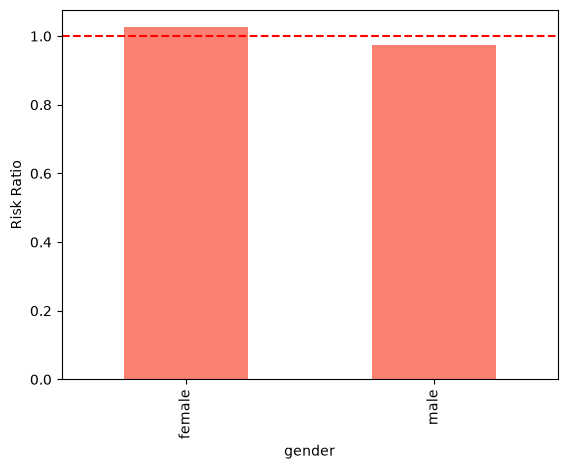



seniorcitizen


,mean,count,diff,risk
seniorcitizen,,,,
0,0.242270,4722,-0.027698,0.897403
1,0.413377,912,0.143409,1.531208


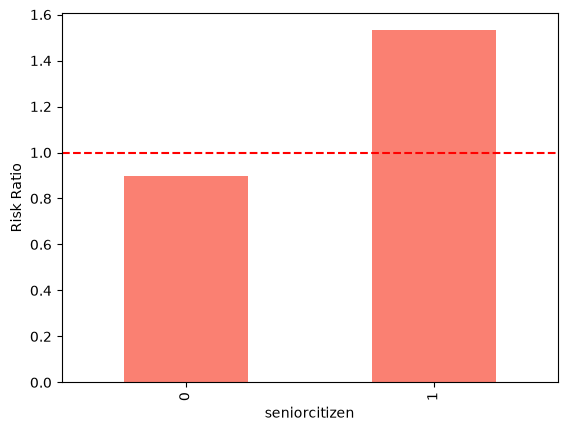



partner


,mean,count,diff,risk
partner,,,,
no,0.329809,2932,0.059841,1.221659
yes,0.205033,2702,-0.064935,0.759472


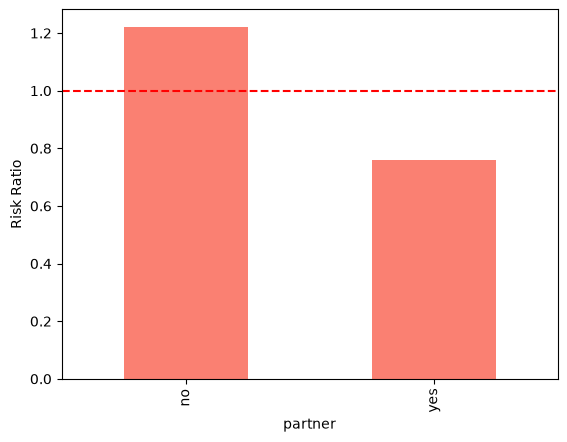



dependents


,mean,count,diff,risk
dependents,,,,
no,0.313760,3968,0.043792,1.162212
yes,0.165666,1666,-0.104302,0.613651


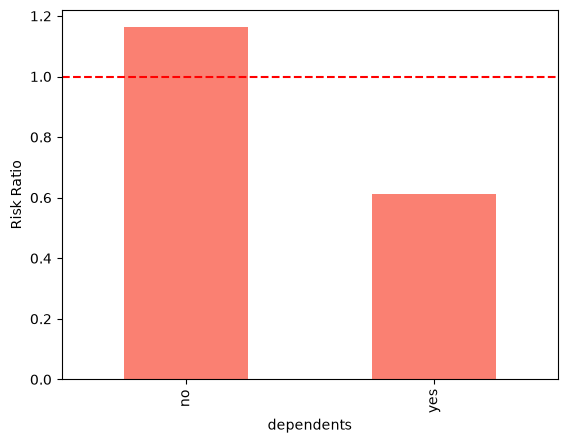



phoneservice


,mean,count,diff,risk
phoneservice,,,,
no,0.241316,547,-0.028652,0.893870
yes,0.273049,5087,0.003081,1.011412


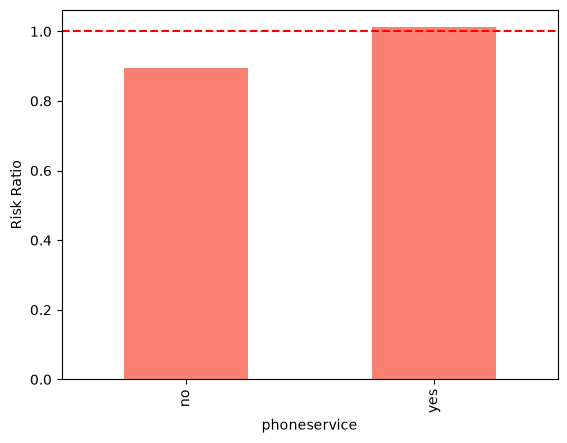



multiplelines


,mean,count,diff,risk
multiplelines,,,,
no,0.257407,2700,-0.012561,0.953474
no_phone_service,0.241316,547,-0.028652,0.893870
yes,0.290742,2387,0.020773,1.076948


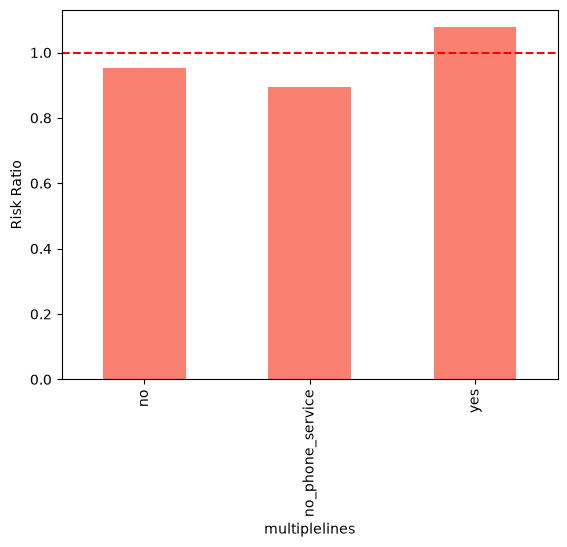



internetservice


,mean,count,diff,risk
internetservice,,,,
dsl,0.192347,1934,-0.077621,0.712482
fiber_optic,0.425171,2479,0.155203,1.574895
no,0.077805,1221,-0.192163,0.288201


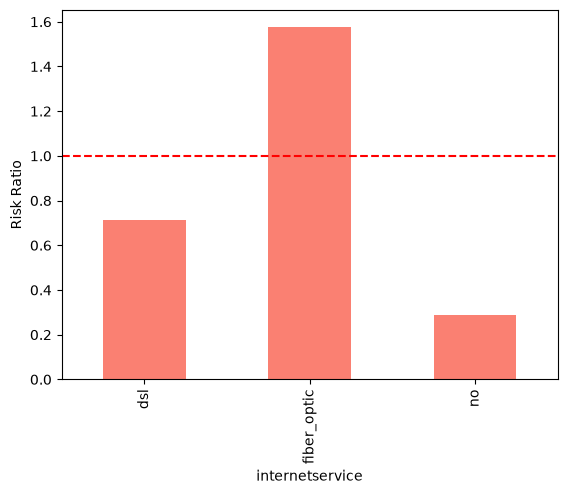



onlinesecurity


,mean,count,diff,risk
onlinesecurity,,,,
no,0.420921,2801,0.150953,1.559152
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.153226,1612,-0.116742,0.567570


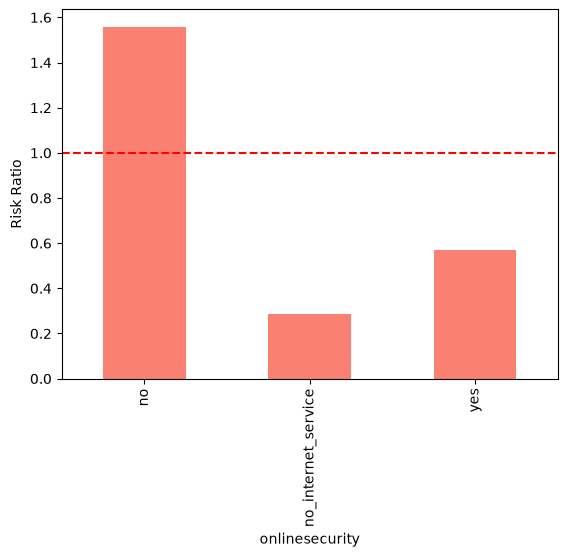



onlinebackup


,mean,count,diff,risk
onlinebackup,,,,
no,0.404323,2498,0.134355,1.497672
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.217232,1915,-0.052736,0.804660


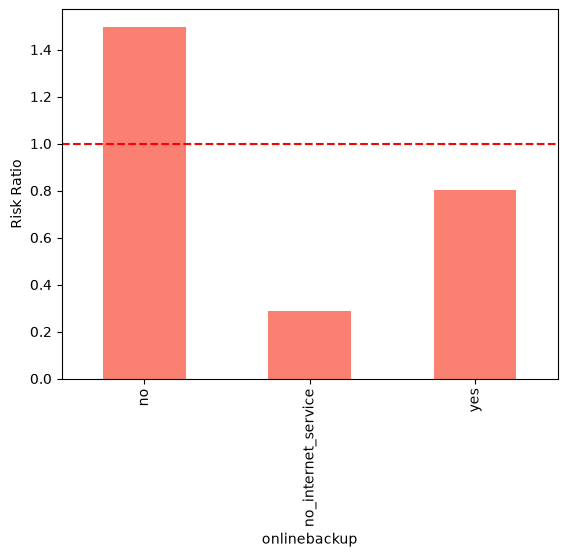



deviceprotection


,mean,count,diff,risk
deviceprotection,,,,
no,0.395875,2473,0.125907,1.466379
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.230412,1940,-0.039556,0.853480


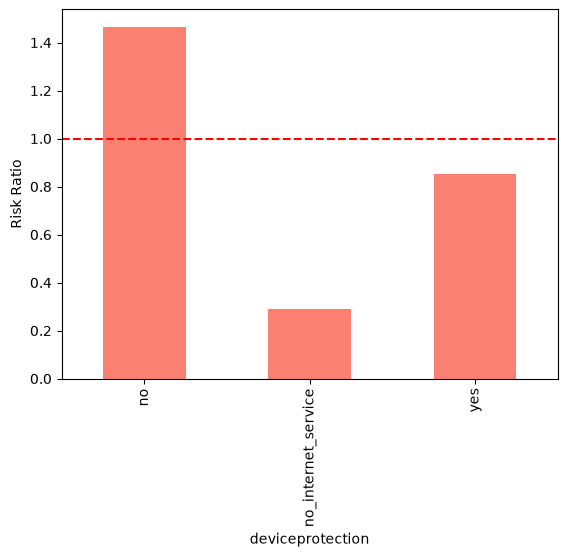



techsupport


,mean,count,diff,risk
techsupport,,,,
no,0.418914,2781,0.148946,1.551717
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.159926,1632,-0.110042,0.592390


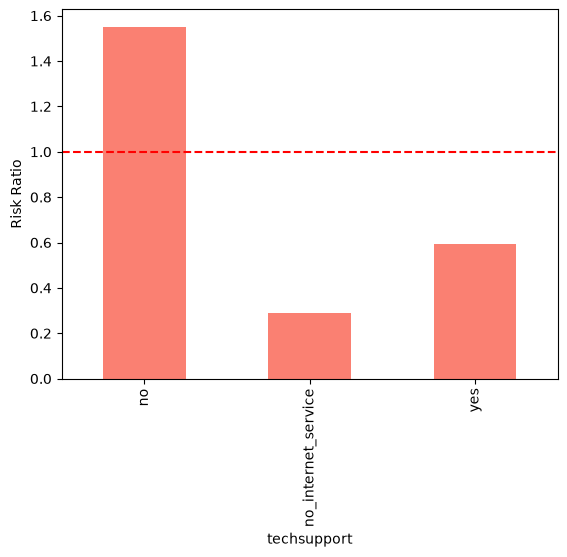



streamingtv


,mean,count,diff,risk
streamingtv,,,,
no,0.342832,2246,0.072864,1.269897
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.302723,2167,0.032755,1.121328


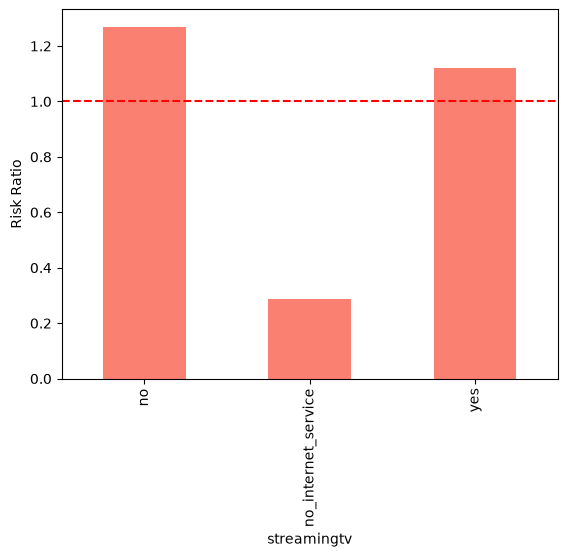



streamingmovies


,mean,count,diff,risk
streamingmovies,,,,
no,0.338906,2213,0.068938,1.255358
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.307273,2200,0.037305,1.138182


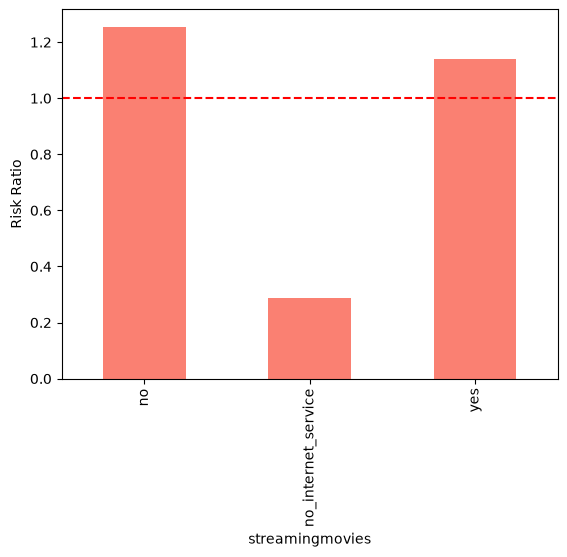



contract


,mean,count,diff,risk
contract,,,,
month-to-month,0.431701,3104,0.161733,1.599082
one_year,0.120573,1186,-0.149395,0.446621
two_year,0.028274,1344,-0.241694,0.104730


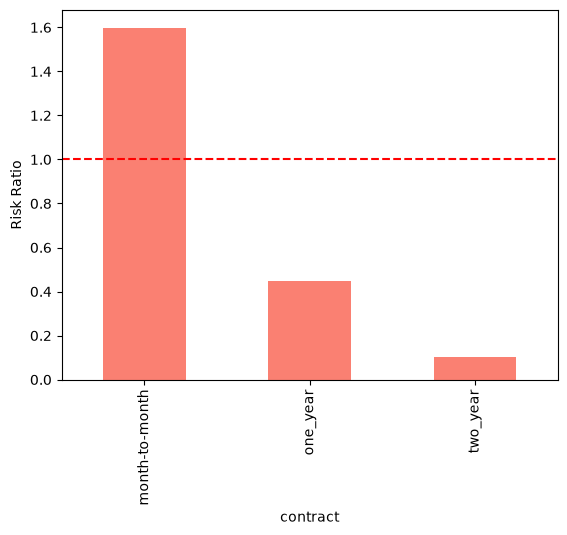



paperlessbilling


,mean,count,diff,risk
paperlessbilling,,,,
no,0.172071,2313,-0.097897,0.637375
yes,0.338151,3321,0.068183,1.252560


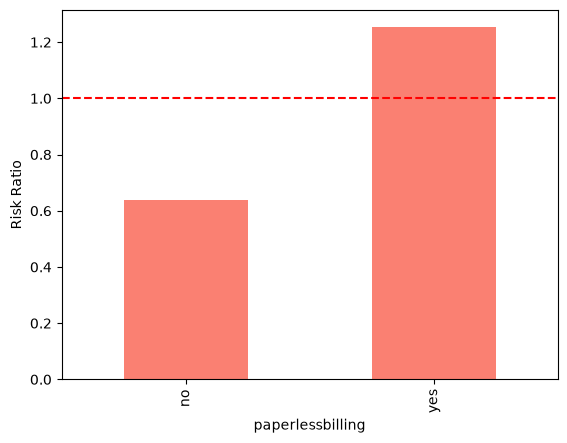



paymentmethod


,mean,count,diff,risk
paymentmethod,,,,
bank_transfer_(automatic),0.168171,1219,-0.101797,0.622928
credit_card_(automatic),0.164339,1217,-0.105630,0.608733
electronic_check,0.455890,1893,0.185922,1.688682
mailed_check,0.193870,1305,-0.076098,0.718121


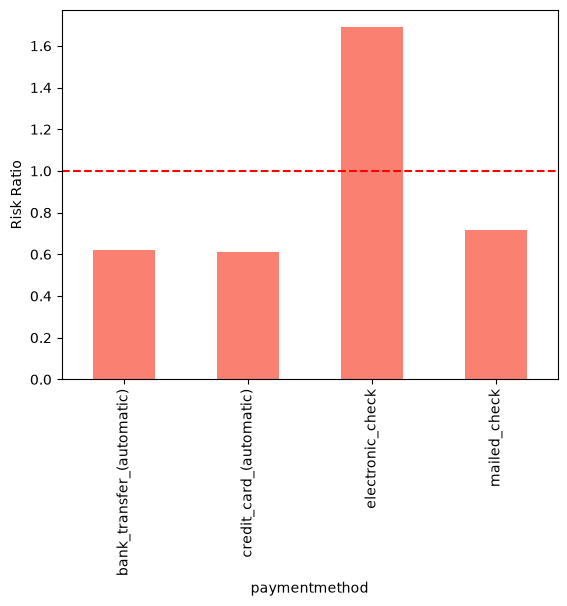

In [52]:
from IPython.display import display
# Inside a loop, a table is not printed automatically, so we use the display function from IPython.display to show each one.

for c in categorical:
    print(c)
    df_group = df_full_train.groupby(c).churn.agg(['mean', 'count'])
    # Note that in this loop the diff column is computed the other way around:
    # as the group mean minus the global mean, so here a positive diff means the group churns more than average.
    df_group['diff'] = df_group['mean'] - global_churn
    df_group['risk'] = df_group['mean'] / global_churn
    display(df_group)

    df_group['risk'].plot(kind='bar', color='salmon')
    plt.axhline(1, color='red', linestyle='--')
    plt.ylabel('Risk Ratio')
    plt.show()

    print()
    print()

Scanning through all 16 tables, some variables stand out:
- For `contract`, customers on a month-to-month contract churn far more than average, while two-year contracts almost never churn
- `internetservice` tells a similar story: fiber optic customers churn much more than DSL customers.
- in `paymentmethod`, customers paying by electronic check are the riskiest group in this table.

So contract type, internet service and payment method look important; gender and phone service do not.  
What these per-group tables cannot do is compare the importance of whole variables with each other. For that we need mutual information, which is the next section.

## 6. Feature Importance: Mutual Information

The churn rate and risk ratio from the previous section tell us which groups within one variable churn more, but they don't let us compare whole variables with each other.  
**Mutual information** fixes that: it is **a single number per variable that measures how important it is**.

### The concept

**Mutual information** is a concept from [information theory](https://en.wikipedia.org/wiki/Mutual_information). It **tells us how much we can learn about one variable if we know the value of another**.

Applied to our project: how much do we learn about churn if we know the customer's contract type? If knowing a feature always gives us useful information about churn, the mutual information between them is high and the feature is important. If the feature tells us nothing, the mutual information is 0.

In this project we use mutual information to measure the importance of categorical variables.

### Measuring Mutual Information with scikit-learn

The function we need is `mutual_info_score` from scikit-learn:

In [53]:
from sklearn.metrics import mutual_info_score

Let's measure it for a few variables.

In [59]:
# For contract:
mutual_info_score(df_full_train.churn, df_full_train.contract)

0.0983203874041556

In [60]:
# For gender:
mutual_info_score(df_full_train.gender, df_full_train.churn)

0.0001174846211139946

In [61]:
# For partner
mutual_info_score(df_full_train.partner, df_full_train.churn)

0.009967689095399745

**The order of the arguments for `mutual_info_score()` doesn't matter because mutual information is symmetric, so `mutual_info_score(df_full_train.contract, df_full_train.churn)` gives the same 0.0983.**

The numbers confirm what we saw with the risk ratios. Contract has by far the highest score: knowing the contract type teaches us a lot about churn. Gender is almost 0: knowing the gender tells us practically nothing. Partner sits in between.

### Applying it to all categorical variables

We could repeat this manually for all 16 variables, but there is a shorter way. `mutual_info_score` takes two arguments, while pandas apply passes one series at a time, so we wrap it in a function of one argument:

In [62]:
def mutual_info_churn_score(series):
    return mutual_info_score(series, df_full_train.churn)

In [66]:
# Now we apply it to every categorical column and sort the result from most to least important.
# pandas.Series.apply(some_function) invokes some function on values of Series.
mi = df_full_train[categorical].apply(mutual_info_churn_score)
# mi is a pandas series
mi.sort_values(ascending=False)

contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

The result puts everything on one scale.  
Contract is the most important categorical variable, followed by onlinesecurity and techsupport: customers without these services churn more, as we saw in the risk ratio tables and graphs.  
At the bottom of the list we find multiplelines, phoneservice and gender: variables that tell us almost nothing about churn.

**This covers the categorical variables. For numerical ones we need a different measure, correlation**, which is the next section.

## 7. Feature Importance: Correlaction

**Mutual information measures the importance of categorical variables.  
For numerical variables we use the correlation coefficient instead**: it tells us how strongly each numerical feature is related to churn.

### The correlation coefficient

The **correlation coefficient** (the **Pearson correlation coefficient**), usually denoted $r$ measures **the degree of dependency between two variables**. It is always a number **between $-1$ and $1$**:
- A value **close to 1** means **strong positive correlation**: when one variable grows, the other grows too.
- A value **close to -1** means **strong negative correlation**: when one variable grows, the other decreases.
- A value **close to 0** means there is **no dependency**: a change in one variable tells us nothing about the other.

**The sign gives the direction of the relationship, and the absolute value gives its strengt**h. One way to interpret the magnitude:
- **LOW** when the absolute value of **r is between 0 and 0.2**
- **MEDIUM** when it is **between 0.2 and 0.5**
- **STRONG** when it is **between 0.5 and 1.0**

<!-- ![Pearson Correlation Coeeficient](https://github.com/k-candidate/machine-learning-zoomcamp/raw/main/03-classification/images/07-correlation-01-correlation-coefficient-imagegen-pilot.jpg) -->

<img src="https://github.com/k-candidate/machine-learning-zoomcamp/raw/main/03-classification/images/07-correlation-01-correlation-coefficient-imagegen-pilot.jpg" alt="Pearson Correlation Coefficient" style="max-width: 100%; height: auto; display: block; margin: 0 auto;">

In our case one of the two variables is churn (a binary 0/1 column).  
If the correlation between a numerical feature and churn is positive, customers with higher values of that feature churn more; if it is negative, they churn less.  
The larger the absolute value, the more important the feature.

$$
\begin{aligned}
y \in \{0, 1\} \quad &x \in \mathbb{R} \\
&\text{\small $-\infty < x < +\infty$} \\
\\
x &= \text{tenure} \\
y &= \text{churn} \\
\\
\text{POSITIVE:} \quad &\text{more tenure} \rightarrow \text{higher churn} \\
\text{NEGATIVE:} \quad &\text{more tenure} \rightarrow \text{less churn}
\end{aligned}
$$

### Correlation of numerical features with churn

We have three numerical variables: `tenure`, `monthlycharges` and `totalcharges`. **Pandas computes their correlation with the target in one call with `corrwith()`**:

In [67]:
df_full_train[numerical].corrwith(df_full_train.churn)

tenure           -0.351885
monthlycharges    0.196805
totalcharges     -0.196353
dtype: float64

Let's read this:
- Tenure has a medium negative correlation. The longer customers stay with the company, the less likely they are to churn.
- Monthly charges have a low-to-medium positive correlation: the more customers pay per month, the more likely they are to churn.
- Total charges have a low-to-medium negative correlation, not surprising, since total charges accumulate with tenure.

To rank features by importance we don't care about the direction, only about the strength, so we take the absolute values:

In [68]:
df_full_train[numerical].corrwith(df_full_train.churn).abs()

tenure            0.351885
monthlycharges    0.196805
totalcharges      0.196353
dtype: float64

Tenure is the most important numerical feature.

### Checking the relationship with groups

We can double-check the correlation by splitting customers into groups and computing the churn rate in each. The same idea we used for categorical variables, now applied to bins of a numerical one.

In [69]:
# Tenure is measured in months and goes up to 72:
df_full_train.tenure.max()

np.int64(72)

In [70]:
# We split it into 3 groups: <= 2mo, 2mo-1y, > 1y
# And look at the chur rate in each
df_full_train[df_full_train.tenure <= 2].churn.mean() 

np.float64(0.5953420669577875)

In [71]:
df_full_train[(df_full_train.tenure > 2) & (df_full_train.tenure <= 12)].churn.mean()

np.float64(0.3994413407821229)

In [72]:
df_full_train[df_full_train.tenure > 12].churn.mean()

np.float64(0.17634908339788277)

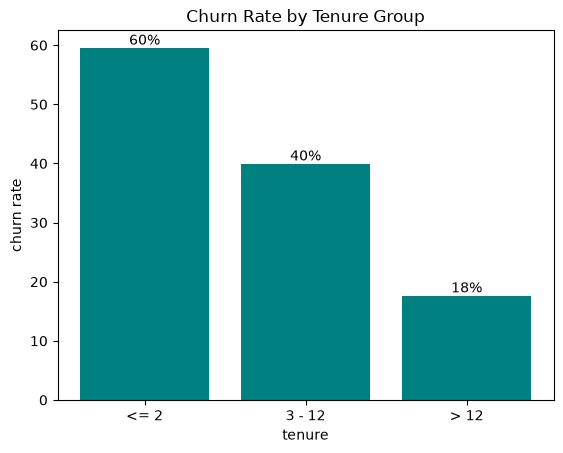

In [89]:
# Let's put it in a graph to visualize it.
rates_tenure = [
    df_full_train[df_full_train.tenure <= 2].churn.mean(),
    df_full_train[
        (df_full_train.tenure > 2) & (df_full_train.tenure <= 12)
    ].churn.mean(),
    df_full_train[df_full_train.tenure > 12].churn.mean(),
]
labels = ["<= 2", "3 - 12", "> 12"]

percentages_tenure = pd.Series(rates_tenure) * 100

# Plot
bars = plt.bar(labels, percentages_tenure, color="teal")
plt.bar_label(bars, fmt="%.0f%%")
plt.title("Churn Rate by Tenure Group")
plt.xlabel("tenure")
plt.ylabel("churn rate")
plt.show()


The pattern is striking.  
Customers who have been with the company for two months or less churn at almost 60%.  
For customers of up to a year it is about 40%.  
And for those who stayed longer than a year only about 18%.  
Churn clearly decreases as tenure grows: exactly what the negative correlation told us.

In [79]:
# The same check for monthly charges:
df_full_train[df_full_train.monthlycharges <= 20].churn.mean()

np.float64(0.08795411089866156)

In [80]:
df_full_train[(df_full_train.monthlycharges > 20) & (df_full_train.monthlycharges <= 50)].churn.mean()

np.float64(0.18340943683409436)

In [81]:
df_full_train[df_full_train.monthlycharges > 50].churn.mean()

np.float64(0.32499341585462205)

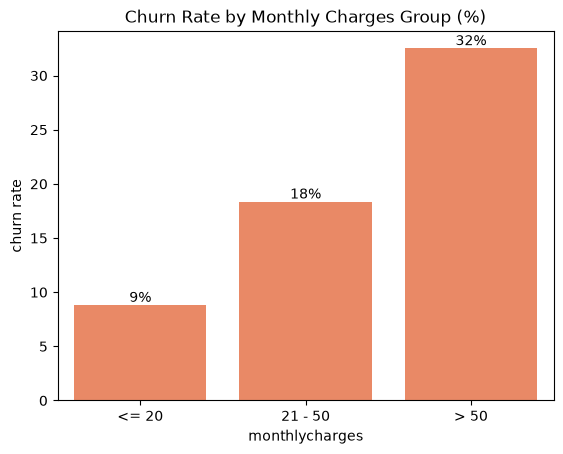

In [94]:
# Let's put it in a graph to visualize it.
# It's the exact same structure, but this time let's use seaborn.

# 1. Slice the monthly charges using our cutoffs
bins = [-float("inf"), 20, 50, float("inf")]
labels = ["<= 20", "21 - 50", "> 50"]
groups = pd.cut(df_full_train["monthlycharges"], bins=bins, labels=labels)

# 2. Plot, calculate the means automatically, and add labels
ax = sns.barplot(
    x=groups, y=df_full_train["churn"] * 100, errorbar=None, color="coral"
)
ax.bar_label(ax.containers[0], fmt="%.0f%%")

# 3. Titles and clean up
plt.title("Churn Rate by Monthly Charges Group (%)")
plt.xlabel("monthlycharges")
plt.ylabel("churn rate")
plt.show()

Here the relationship goes the other way: customers paying at most $20 churn at about 9%, and customers paying more than $50 churn at about 32%.  
The more people pay monthly, the more likely they are to leave: positive correlation confirmed.

We now know the importance of **categorical variables (mutual information)** and **numerical variables (correlation)**.  
Next we prepare the categorical variables for the model with one-hot encoding.

## 8. One-Hot Encoding

In this section **we encode categorical features as numbers, so they can be used by a machine learning model**.  
The technique is called **one-hot encoding**, and **Scikit-Learn gives us a convenient way to do it with DictVectorizer**.

### Why we need encoding

So far we looked at categorical variables one at a time: churn rate per contract type, risk ratio per payment method, mutual information.  
That told us which features are useful. 

Now **we want to put all the features together into one matrix and train a model on it**.

**Machine learning models work with numbers**. Our numerical variables (`tenure`, `monthlycharges`, `totalcharges`) are already numbers.  
But `contract` contains strings like `two_year`, and `paymentmethod` contains strings like `electronic_check`.  
We cannot multiply a string by a weight, so we need to translate these values into numbers first.

### One-hot encoding

One-hot encoding replaces one categorical column with several binary columns, one per category.  
Each new column says whether the row has that category (1) or not (0).

For example, in our dataset `contract` has three possible values: `month-to-month`, `one_year` and `two_year`.  One row of the dataset:
```
{"contract": "two_year", "tenure": 72, "monthlycharges": 115.5}
```
becomes
```
contract=month-to-month  contract=one_year  contract=two_year  tenure  monthlycharges
                      0                  0                  1      72           115.5
```

**Only one of the contract columns is "hot" (set to 1). That is where the name one-hot encoding comes from.**

The same transformation can be shown directly as a table. Each categorical value becomes a binary column, and exactly one column is `1` within each feature group:

| Gender | Contract | `gender=F` | `gender=M` | `contract=M` | `contract=1Y` | `contract=2Y` |
|---|---|---:|---:|---:|---:|---:|
| F | 2Y | 1 | 0 | 0 | 0 | 1 |
| F | 1Y | 1 | 0 | 0 | 1 | 0 |
| M | M | 0 | 1 | 1 | 0 | 0 |
| M | 1Y | 0 | 1 | 0 | 1 | 0 |
| F | 1Y | 1 | 0 | 0 | 1 | 0 |
| M | M | 0 | 1 | 1 | 0 | 0 |
| M | 2Y | 0 | 1 | 0 | 0 | 1 |

We do this for every categorical feature. The `paymentmethod` feature has four values, so it becomes four columns. `gender` has two values, so it becomes two columns. The numerical features pass through unchanged (we keep them as they are).

### Turning rows into dictionaries

**scikit-learn's `DictVectorizer` takes a list of dictionaries, one dictionary per row. We convert a dataframe to this format with pandas:**

```
dicts = df[categorical + numerical].to_dict(orient='records')
```
pandas.DataFrame.to_dict's agument "orient" determines the type of the values of the dictionary. There are multiple possible values.
See official doc: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_dict.html

The `orient='records'` argument means "one dictionary per row". After this, dicts is a list that looks like this:
```
[{'contract': 'two_year', 'tenure': 72, 'monthlycharges': 115.5},
 {'contract': 'month-to-month', 'tenure': 10, 'monthlycharges': 95.25},
 ...]
```

### DictVectorizer

`DictVectorizer` lives in `sklearn.feature_extraction`:

In [96]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

**Like every Scikit-Learn transformer, it has a `fit` step and a `transform` step:**
- **`fit` learns the list of categories for each column**
- **`transform` turns dictionaries into a matrix**

**`fit_transform` does both in one call.**  
**With `sparse=False` the result is a usual NumPy array.**  
**By default DictVectorizer returns a sparse matrix (a data structure that stores only the non-zero elements), because most of the matrix is zeros.**  
**Sparse matrices are more memory efficient, but for this dataset it is simpler to work with a dense array.**

**To see what columns the vectorizer created, use `dv.get_feature_names_out()`.**  
For the full dataset we get 45 names: one column per category value (`contract=month-to-month`, `internetservice=fiber_optic`, ...) plus the three numerical columns. The resulting matrix has 45 columns, one per feature name:

In [103]:
dv.get_feature_names_out()

array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'dependents=no', 'dependents=yes',
       'deviceprotection=no', 'deviceprotection=no_internet_service',
       'deviceprotection=yes', 'gender=female', 'gender=male',
       'internetservice=dsl', 'internetservice=fiber_optic',
       'internetservice=no', 'monthlycharges', 'multiplelines=no',
       'multiplelines=no_phone_service', 'multiplelines=yes',
       'onlinebackup=no', 'onlinebackup=no_internet_service',
       'onlinebackup=yes', 'onlinesecurity=no',
       'onlinesecurity=no_internet_service', 'onlinesecurity=yes',
       'paperlessbilling=no', 'paperlessbilling=yes', 'partner=no',
       'partner=yes', 'paymentmethod=bank_transfer_(automatic)',
       'paymentmethod=credit_card_(automatic)',
       'paymentmethod=electronic_check', 'paymentmethod=mailed_check',
       'phoneservice=no', 'phoneservice=yes', 'seniorcitizen',
       'streamingmovies=no', 'streamingmovies=no_internet_service',

In [98]:
X_train.shape

(4225, 45)

4225 is the number of rows in the training set, 45 is the number of features after encoding.  
We can see those 45 in the previous command as well, but let's not count it by hand and just use the np array's shape:

In [104]:
dv.get_feature_names_out().shape

(45,)

### Encoding the validation set

The validation set must be encoded in exactly the same way as the training set.  
That is why **we call fit only on the training data. For the validation data we reuse the already fitted vectorizer and call only transform:**

In [105]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

**If we called `fit` again on validation, the columns could come out in a different order, or a category that appears only in validation would create a new column.  
The matrix would no longer match the one the model was trained on.**

### Alternative: OneHotEncoder

Scikit-Learn also has a dedicated `OneHotEncoder` class that works on dataframes directly instead of dictionaries. But we have not used it here.  
Official doc: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html.

## 9. Logistic Regression

In this section we look at logistic regression: the model we will use for churn prediction.  
We see how it relates to linear regression from the previous chapter, implement the sigmoid function, and write the model in code.

### Binary Classification

Our problem (predicting churn) is a binary classification problem: the target variable takes one of two values.  
We encoded it as 1 for customers who churned (the positive class) and 0 for customers who stayed (the negative class).  
Spam detection is another example: 1 for spam, 0 for not spam.

A supervised model is a function that maps features to the target:
$$g(x_{i}) \approx y_{i}$$

For classification, the output of $g$ is a number between 0 and 1: the probability that $x_i$ belongs to the positive class.  
If the model outputs 0.8 for a customer, we say it believes there is an 80% chance this customer will churn.

### From Linear Regression to Logistic Regression

In the previous chapter we used linear regression, which computes a weighted sum of the features:
$$g(x_i) = w_0 + w_{1}x_{1} + w_{2}x_{2} + ... + w_{n}x_{n}$$
Here $w_0$ is the bias term (what we predict when all features are zero); and $w_1 ... w_n$ are the weights, each one says how much its feature contributes to the prediction.  
The output can be any real number, which is fine for predicting a price, but a probability must stay between 0 and 1.

**Logistic regression is the same linear model with one extra step: we apply the sigmoid function to the weighted sum:**
$$g(x_i) = Sigmoid(w_0 + w_{1}x_{1} + w_{2}x_{2} + ... + w_{n}x_{n})$$

And what's this sigmoid function?
$$Sigmoid(z) = \frac{1}{1 + e^{-z}} = \frac{1}{1 + \exp(-x)}$$

<img src="https://github.com/k-candidate/machine-learning-zoomcamp/raw/main/03-classification/images/09-logistic-regression-03-sigmoid-formula-clean.jpg" alt="Sigmoid chart" style="max-width: 100%; height: auto; display: block; margin: 0 auto;">

**The sigmoid squashes any real number into the range between 0 and 1.**  
**That turns the raw score into a probability.**  
**Both models are called linear models, because the score inside is still a linear combination of the features, only the final transformation differs.**

### The sigmoid function

In [113]:
# In NumPy:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [114]:
sigmoid(10000)

np.float64(1.0)

In [124]:
sigmoid(-700).round()

np.float64(0.0)

In [125]:
sigmoid(0)

np.float64(0.5)

A large positive score maps to 1.0.  
A large negative score maps to 0.  
And at exactly 0 the sigmoid gives 0.5 (a coin flip).  

To see the shape, we evaluate the sigmoid on values from -7 to 7 and plot it:

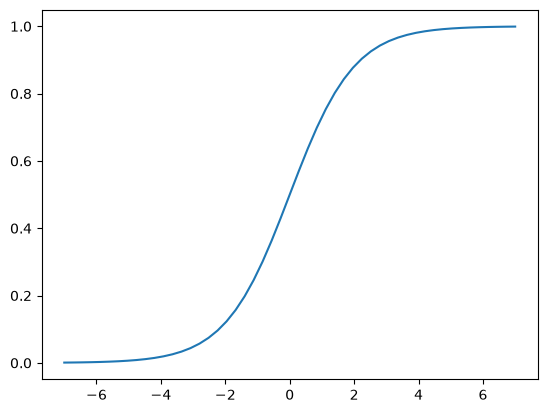

In [128]:
z = np.linspace(-7, 7, 51)
plt.plot(z, sigmoid(z))

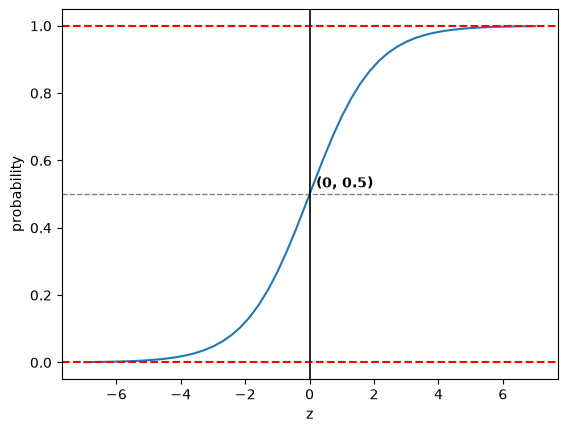

In [129]:
# Fancier
plt.plot(z := np.linspace(-7, 7), 1 / (1 + np.exp(-z)))
plt.axhline(0, color="red", linestyle="--", linewidth=1.5)    # Lower bound
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1.0) # Restored middle guide
plt.axhline(1, color="red", linestyle="--", linewidth=1.5)    # Upper bound
plt.axvline(0, color="black", linewidth=1.2)                  # Y-axis reference

plt.text(0.2, 0.52, "(0, 0.5)", fontsize=10, weight="bold")
plt.xlabel("z")
plt.ylabel("probability")
plt.show()

**The curve has an S shape: scores below roughly -5 give a probability close to 0, scores above roughly 5 give a probability close to 1, and everything in between moves smoothly between the two extremes.  
A score of 0 means a 50% chance.**

### Implementing the models

Here is linear regression from the previous module, written out with a loop:

In [130]:
def linear_regression(xi):
    result = w0
    
    for j in range(len(w)):
        result = result + xi[j] * w[j]
        
    return result

**Logistic regression needs only one change: pass the score through the sigmoid before returning it.**

In [131]:
def logistic_regression(xi):
    score = w0
    
    for j in range(len(w)):
        score = score + xi[j] * w[j]
        
    result = sigmoid(score)
    return result

**The two functions are almost identical.  
That is the whole idea: logistic regression is linear regression with a sigmoid on top, which makes the output interpretable as a probability.**

In the next section we stop implementing things by hand and train this model with Scikit-Learn.

## 10. Training Logistic Regression with scikit-learn

In this section we:
- train a logistic regression model on the encoded training data
- apply it to the validation dataset
- measure how good it is (its accuracy)

### Training the model

**scikit-learn has a ready-made implementation of logistic regression.**  
Training it follows the same pattern as LinearRegression in the previous section: **create the model, then call `fit` with the feature matrix and the target vector.**

In [132]:
from sklearn.linear_model import LogisticRegression

In [204]:
model = LogisticRegression(solver='lbfgs')
# solver='lbfgs' is the default solver in version 1.9.1 of scikit-learn
# for older versions, you need to specify it explicitly
# See the official doc: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

A warning (ConvergenceWarning) displays. I silenced it. But here's the explanation:

#### What the Warning Means and Why It Is Happening

The ConvergenceWarning indicates that the machine learning model stopped training before it finished finding the mathematically optimal patterns in the data.

It is technically just a warning, meaning the code will still run, and scikit-learn will still output a model. However, we should never ignore it. Because the model cut its training short, the underlying mathematical weights are incomplete, meaning the final classification predictions are likely to be inaccurate or underperforming.

#### The Root Cause: A Massive Clash in Data Scales

The error happens because of a direct conflict between the default settings of the lbfgs optimization solver and the exact structure of our X_train dataset:
1. How the Solver Works: Think of the lbfgs solver as a hiker climbing a mountain in a thick fog, trying to find the highest peak (the most accurate weights). It takes up to 100 steps (max_iter=100 which is the default as per the doc https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) to find that peak before it times out.
2. The Conflict in our Data: our dataset contains two completely different types of numbers. These numbers can be seen in the next code cell.
    - 43 columns are binary / one-hot encoded flags (values between 0 and 1).
	- 1 column has an average value of 2,254.8.
3. The Resulting Failure: Because that final column has numbers that are thousands of times larger than the others, it warps the map. The hiker completely loses orientation—taking massive, erratic strides to accommodate the large column while making no progress on the small ones. After 100 steps, the hiker is still lost in the fog, hits the built-in step limit, and triggers the timeout warning.

#### What we would need to do

To fix this, we must accommodate the optimization hiker using one of two strategies:
- Option A: Give the hiker more time. We can manually increase max_iter (e.g., max_iter=1000). This gives the hiker enough time to survive the erratic paths and eventually hit the peak. In our case, I tested it with bigger numbers and it did not work.
- Option B: Smooth out the map. We can use StandardScaler. This shifts our data columns so that every single feature balances smoothly around a center of 0 with a spread of 1. On a perfectly leveled map, the lbfgs hiker easily navigates the path and reaches the optimal solution well under the 100-step limit.

The code for option B would look like this:
```python
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 1. Create a pipeline that automatically scales data before fitting
pipeline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver='lbfgs')
)

# 2. Fit the pipeline using the raw NumPy arrays
pipeline_model.fit(X_train, y_train)
```
I have tested it and it works fine.

In [143]:
means = np.mean(X_train, axis=0)
stds = np.std(X_train, axis=0)

print("Means per column:\n", np.round(means, 3))
print("\nStandard deviations per column:\n", np.round(stds, 3))

Means per column:
 [5.450000e-01 2.160000e-01 2.400000e-01 6.990000e-01 3.010000e-01
 4.380000e-01 2.210000e-01 3.410000e-01 4.970000e-01 5.030000e-01
 3.420000e-01 4.370000e-01 2.210000e-01 6.450200e+01 4.760000e-01
 9.800000e-02 4.260000e-01 4.440000e-01 2.210000e-01 3.350000e-01
 4.960000e-01 2.210000e-01 2.830000e-01 4.140000e-01 5.860000e-01
 5.210000e-01 4.790000e-01 2.190000e-01 2.150000e-01 3.340000e-01
 2.310000e-01 9.800000e-02 9.020000e-01 1.640000e-01 3.910000e-01
 2.210000e-01 3.880000e-01 3.940000e-01 2.210000e-01 3.840000e-01
 4.890000e-01 2.210000e-01 2.900000e-01 3.212700e+01 2.254824e+03]

Standard deviations per column:
 [4.980000e-01 4.110000e-01 4.270000e-01 4.590000e-01 4.590000e-01
 4.960000e-01 4.150000e-01 4.740000e-01 5.000000e-01 5.000000e-01
 4.740000e-01 4.960000e-01 4.150000e-01 3.017400e+01 4.990000e-01
 2.970000e-01 4.940000e-01 4.970000e-01 4.150000e-01 4.720000e-01
 5.000000e-01 4.150000e-01 4.500000e-01 4.930000e-01 4.930000e-01
 5.000000e-01 5.000000

In [147]:
# Let's silence the warning and push through. Let's see where this leads us. Anyway, the principles remain the same.
import warnings
from sklearn.exceptions import ConvergenceWarning
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)
    model = LogisticRegression(solver='lbfgs')
    model.fit(X_train, y_train)

**The `solver` is the optimization algorithm that finds the best weights**.  
**After `fit`, the model has learned both parts of the formula from the previous section. The bias term `w0` is in `intercept_`**:

In [153]:
model.intercept_

array([-0.11092874])

**The weights are in `coef_`: one weight for each of the 45 columns that `DictVectorizer` produced**

In [155]:
model.coef_.round(3)

array([[ 0.564, -0.154, -0.519, -0.013, -0.095,  0.071, -0.098, -0.082,
        -0.033, -0.076, -0.354,  0.343, -0.098,  0.002, -0.251,  0.162,
        -0.02 ,  0.066, -0.098, -0.076,  0.251, -0.098, -0.261, -0.228,
         0.119, -0.121,  0.012, -0.095, -0.03 ,  0.045, -0.028,  0.162,
        -0.271,  0.221, -0.097, -0.098,  0.087, -0.05 , -0.098,  0.039,
         0.194, -0.098, -0.205, -0.072,  0.   ]])

In [164]:
# Just for funsies, let's see what the pipeline model with the scaled dataset will give us
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 1. Create a pipeline that automatically scales data before fitting
pipeline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver='lbfgs')
)

# 2. Fit the pipeline using the raw NumPy arrays
pipeline_model.fit(X_train, y_train)

print(pipeline_model['logisticregression'].intercept_)
print(pipeline_model['logisticregression'].coef_.round(3))

[-1.7117446]
[[ 0.303 -0.021 -0.334  0.016 -0.016  0.041 -0.09   0.036  0.01  -0.01
  -0.282  0.344 -0.09  -0.623 -0.093  0.009  0.088  0.043 -0.09   0.034
   0.119 -0.09  -0.05  -0.089  0.089 -0.031  0.031 -0.03  -0.009  0.042
  -0.009  0.009 -0.009  0.072 -0.066 -0.09   0.142 -0.046 -0.09   0.123
   0.097 -0.09  -0.025 -1.586  0.795]]


### Making Predictions

**The model has two prediction methods**, and the difference matters:
- **`model.predict(X)` gives hard predictions: the final 0/1 answer**
- **`model.predict_proba(X)` gives soft predictions: the actual probabilities**

We want the probabilities, because we will apply our own threshold:

In [165]:
y_pred = model.predict_proba(X_val)[:, 1]

**`predict_proba` returns a matrix with two columns: the probability of class 0 and the probability of class 1.  
The two columns always sum up to 1, so it is enough to take the second one, hence `[:, 1]`.**

**Now we decide: if the model thinks the probability of churn is 50% or more, we predict that the customer will churn:**

In [166]:
churn_decision = (y_pred >= 0.5)

The result is a boolean array. We can use it to select the customers the model thinks will churn. For example, the ones who should receive a promotional email with a discount. Selecting the validation rows with this mask gives 322 customers.

In [171]:
churn_decision[churn_decision == True].shape

(322,)

In [173]:
churn_decision[churn_decision == False].shape

(1087,)

322 + 1087 = 1409 which is the total size of this dataset.

In [178]:
# Just for funsies, let's see what the pipeline model with the scaled dataset thinks
y_pred_pipeline_model = pipeline_model.predict_proba(X_val)[:, 1]
churn_decision_pipeline_model = (y_pred_pipeline_model >= 0.5)
print(churn_decision_pipeline_model[churn_decision_pipeline_model == True].shape)
print(churn_decision_pipeline_model[churn_decision_pipeline_model == False].shape)
# Count True predictions more elegantly
print("Churn (True):", churn_decision_pipeline_model.sum())
# Count False predictions more elegantly
print("No Churn (False):", (~churn_decision_pipeline_model).sum())

(314,)
(1095,)
Churn (True): 314
No Churn (False): 1095


### Accuracy

**To see whether these predictions are any good, we compare them with the actual labels of the validation set:**

In [179]:
(y_val == churn_decision).mean()

np.float64(0.801277501774308)

In [181]:
# Just for funsies, let's see the same thing in the pipeline model with the scaled dataset
(y_val == churn_decision_pipeline_model).mean()
# Pffft. A difference of 0.3%

np.float64(0.8041163946061036)

This metric is **accuracy**: **the fraction of predictions the model got right**.  
Here it is 80%: **in 80% of the cases, the model predicted churn or no churn correctly**.

We can also look at it from a dataframe. Let's put the predictions and the actual values side by side:

In [182]:
df_pred = pd.DataFrame()
df_pred['probability'] = y_pred
df_pred['prediction'] = churn_decision.astype(int)
df_pred['actual'] = y_val

And mark the rows where the prediction matches the reality:

In [183]:
df_pred['correct'] = df_pred.prediction == df_pred.actual
df_pred.correct.mean()

np.float64(0.801277501774308)

Same number, as expected. **Taking the mean of a boolean column counts the fraction of `True` values, because True is 1 and False is 0.**

**An accuracy of 80% is a reasonable start for this problem.** 

**The choice of the 0.5 threshold affects this number**. We will see how to pick a better threshold when we look at classification metrics in more detail.

## 11. Model Interpretation

In this section we look inside the trained model: we match each weight with its feature name, and then train a smaller model on three features to see clearly how the weights work.

### Looking at the coefficients

The model we trained has 45 weights, but `model.coef_[0]` is just an array of numbers: we do not know which weight belongs to which column. Let's pair them up.

First, a quick reminder of how `zip` works. It takes two sequences and joins them element by element:

In [184]:
a = [1, 2, 3, 4]
b = 'abcd'
dict(zip(a, b))

{1: 'a', 2: 'b', 3: 'c', 4: 'd'}

We can do the same with the feature names and the weights:

In [185]:
dict(zip(dv.get_feature_names_out(), model.coef_[0].round(3)))

{'contract=month-to-month': np.float64(0.564),
 'contract=one_year': np.float64(-0.154),
 'contract=two_year': np.float64(-0.519),
 'dependents=no': np.float64(-0.013),
 'dependents=yes': np.float64(-0.095),
 'deviceprotection=no': np.float64(0.071),
 'deviceprotection=no_internet_service': np.float64(-0.098),
 'deviceprotection=yes': np.float64(-0.082),
 'gender=female': np.float64(-0.033),
 'gender=male': np.float64(-0.076),
 'internetservice=dsl': np.float64(-0.354),
 'internetservice=fiber_optic': np.float64(0.343),
 'internetservice=no': np.float64(-0.098),
 'monthlycharges': np.float64(0.002),
 'multiplelines=no': np.float64(-0.251),
 'multiplelines=no_phone_service': np.float64(0.162),
 'multiplelines=yes': np.float64(-0.02),
 'onlinebackup=no': np.float64(0.066),
 'onlinebackup=no_internet_service': np.float64(-0.098),
 'onlinebackup=yes': np.float64(-0.076),
 'onlinesecurity=no': np.float64(0.251),
 'onlinesecurity=no_internet_service': np.float64(-0.098),
 'onlinesecurity=yes

Now each weight has a name. The interpretation is the same as in linear regression: a positive weight pushes the score (and therefore the predicted probability) up, a negative weight pushes it down.

Some of what we see matches the feature importance analysis from the beginning of the module. Recall that `internetservice=fiber_optic` had a high churn risk and `contract=month-to-month` too, both get clearly positive weights. Customers with `contract=two_year` almost never churn, and its weight is the most negative one.

Note how the one-hot encoding works here. In the formula, every category of a feature has its own weight, but for any given customer only one of them is multiplied by 1. All the others are multiplied by 0. So for contract, a month-to-month customer only "uses" the weight 0.564, a two-year customer only the weight -0.519.

The weights of the full model are a bit hard to trust individually: there are many correlated features, and 45 weights is a lot to look at. Let's train a smaller model.


### A smaller model

We take three features: `contract`, `tenure` and `monthlycharges`, the ones that looked most important during EDA:

In [186]:
small = ['contract', 'tenure', 'monthlycharges']

dicts_train_small = df_train[small].to_dict(orient='records')
dicts_val_small = df_val[small].to_dict(orient='records')

We encode them with a fresh DictVectorizer:

In [187]:
dv_small = DictVectorizer(sparse=False)
dv_small.fit(dicts_train_small)

DictVectorizer(sparse=False)

This time the vectorizer creates only five columns:

In [188]:
dv_small.get_feature_names_out()

array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'monthlycharges', 'tenure'], dtype=object)

Three binary columns for the contract categories, plus the two numerical features. Train the model on this small matrix:

In [189]:
X_train_small = dv_small.transform(dicts_train_small)

model_small = LogisticRegression(solver='lbfgs')
model_small.fit(X_train_small, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

Let's look at what it learned. The bias term:

In [190]:
w0 = model_small.intercept_[0]
w0

np.float64(-2.477957595829565)

The weights, paired with their names:

In [191]:
w = model_small.coef_[0]
dict(zip(dv_small.get_feature_names_out(), w.round(3)))

{'contract=month-to-month': np.float64(0.971),
 'contract=one_year': np.float64(-0.024),
 'contract=two_year': np.float64(-0.948),
 'monthlycharges': np.float64(0.027),
 'tenure': np.float64(-0.036)}

Now the picture is much clearer:
- Compared to a two-year contract (weight -0.948), being on month-to-month (weight +0.971) pushes churn probability up a lot
- Each extra month of tenure slightly decreases it (-0.036 per month)
- Monthly charges slightly increase it (+0.027 per dollar)

### Scoring a customer by hand

With five numbers we can compute a prediction manually.  
Take a customer on a two-year contract, paying $30 per month, with 24 months of tenure. The score is the bias plus the weighted features (only one of the three contract weights applies, because only one of them is 1):

In [192]:
-2.47 + (-0.948) + 30 * 0.027 + 24 * (-0.036)

-3.472

The score is -3.472. To turn it into a probability, apply the sigmoid.  
In a notebook, the underscore _ refers to the output of the previous cell:

In [193]:
sigmoid(_)

np.float64(0.03011950191351196)

Only a 3% chance of churn: exactly what we would expect from a loyal customer on a two-year contract.

Try another one: month-to-month contract, $50 per month, 5 months of tenure. The score is -2.47 + 0.971 + 50 * 0.027 - 5 * 0.036 = -0.329, and the sigmoid of that is about 0.418, a 42% churn risk.

One useful observation: the sigmoid of 0 is 0.5. So if the score is positive, the customer is more likely to churn than not; if it is negative, less likely. In the example above the score was -0.329, just below the middle.

## 12. Using the Model

The model is ready. In this section we do the final step of the project: retrain it on the full training data (train plus validation), check it on the held-out test set, and score individual customers with it.

### Final Model

During training and tuning we kept the test set untouched. Now that we no longer need the validation set for checking the model, we can use that data for training too. More data usually means a slightly better model. That is exactly what `df_full_train` is for:

In [196]:
dicts_full_train = df_full_train[categorical + numerical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(dicts_full_train)

y_full_train = df_full_train.churn.values

In [202]:
warnings.filterwarnings("ignore", category=ConvergenceWarning)
model = LogisticRegression(solver='lbfgs')
model.fit(X_full_train, y_full_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

**Note that we fit a new `DictVectorizer` on the full training data as well. The encoding and the model always go together.**

### Checking on the test set

Now we take the test set, encode it with the same vectorizer, and compute the predictions:

In [198]:
dicts_test = df_test[categorical + numerical].to_dict(orient='records')
X_test = dv.transform(dicts_test)

y_pred = model.predict_proba(X_test)[:, 1]
churn_decision = (y_pred >= 0.5)
(churn_decision == y_test).mean()

np.float64(0.8140525195173882)

Accuracy on the test set is about 81.4%. On validation we had 80.1%. The two numbers are close, which is what we want to see: **the model performs on unseen data about as well as on the data it was tuned with. A large gap between the two would be a sign of overfitting.**

### Scoring one customer

In practice we will not score a whole test set. We score customers one by one. Each customer is one row of our data, so one dictionary. Take the last customer from the test set:

In [199]:
customer = dicts_test[-1]
customer

{'gender': 'female',
 'seniorcitizen': 0,
 'partner': 'yes',
 'dependents': 'yes',
 'phoneservice': 'yes',
 'multiplelines': 'yes',
 'internetservice': 'fiber_optic',
 'onlinesecurity': 'yes',
 'onlinebackup': 'no',
 'deviceprotection': 'yes',
 'techsupport': 'no',
 'streamingtv': 'yes',
 'streamingmovies': 'yes',
 'contract': 'month-to-month',
 'paperlessbilling': 'yes',
 'paymentmethod': 'electronic_check',
 'tenure': 17,
 'monthlycharges': 104.2,
 'totalcharges': 1743.5}

**The vectorizer expects a list of dictionaries, so we wrap the customer in a list. `transform` (not `fit_transform`), because the vectorizer is already fitted:**

In [200]:
X_small = dv.transform([customer])
model.predict_proba(X_small)[0, 1]

np.float64(0.6613470087309817)

The model gives this customer a 66% chance of churning. Since that is above our 0.5 threshold, the decision is "churn".  
And indeed, this customer actually churned in the data:

In [201]:
y_test[-1]

np.int64(1)

This is how the model would be used in a real project. A service receives the customer's data as a dictionary, encodes it with the vectorizer, and asks the model for a probability. If it is above the threshold (for example, 0.5) the business sends this customer a promotional email with a discount, hoping to keep them.

<img src="https://github.com/k-candidate/machine-learning-zoomcamp/raw/main/03-classification/images/12-using-log-reg-04-production-diagram-imagegen.jpg" alt="production diagram" style="max-width: 100%; height: auto; display: block; margin: 0 auto;">

The model itself is just numbers (weights and the bias term) and the vectorizer with the list of categories. To use it outside the notebook we would need to save both to a file, which is what we cover in a later chapter.

## 13. Summary

The dataset was the Telco churn data: about 7,000 customers of a telecom company, with information about their contracts, services and payments.

What we did:
- Data preparation: cleaned up column names, fixed the `totalcharges` column, and converted the target to 0/1
- Validation framework: split the data into train, validation and test (60%/20%/20%) with Scikit-Learn
- EDA: looked at missing values, the target variable, and the distribution of the features
- Feature importance: measured the risk ratio and difference for categorical features, mutual information (`contract` was the most informative one, 0.098), and the correlation coefficient for numerical features (`tenure` was the most correlated, 0.35)
- One-hot encoding: turned categorical variables into binary columns with `DictVectorizer`, ending up with a 45-column feature matrix
- Logistic regression: trained it with Scikit-Learn, reached about 80% accuracy on validation and 81.5% on test
- Model interpretation: matched weights to feature names with `zip`, trained a smaller model on `contract`, `tenure` and `monthlycharges`, and computed a prediction by hand
- Using the model: retrained on the full training data and scored individual customers

<style>
/* 1. Forces wide tables and standard HTML outputs to fit */
.output_subarea, .output_html, table.dataframe {
    max-width: 100% !important;
    overflow-x: auto !important;
    display: block !important;
}

/* 2. Forces standard stdout code prints, stderr outputs (like wget), 
      and Python Traceback errors to wrap text safely */
div.output_area pre, 
div.output_subarea.output_stream.output_stderr pre, 
div.output_subarea.output_error pre {
    white-space: pre-wrap !important;
    word-break: break-word !important;
}
</style>
